# Ruteo seguro con pesos — elegir λ (Eje 2)

El modelo no calcula rutas: da el **riesgo de cada calle**. Aquí ese riesgo se vuelve el **peso de un grafo** y se busca el camino de menor costo
con **Dijkstra** (`scipy.sparse.csgraph`), con costo por calle

> `costo = largo × (1 + λ · riesgo)`  (riesgo en [0, 1]; λ = 0 es la ruta más corta)

El valor de λ **no se fija a ojo**: se parte de lo que usan otros sistemas y proyectos de rutas seguras, se barre en una grilla y se elige con una regla explícita
(desvío máximo aceptable) midiendo contra **lo que realmente ocurrió en 2023** con un riesgo calculado solo con datos hasta 2022, y se confirma después en el **test (enero–agosto de 2024)**.

| Punto de partida (documentación) | Forma del costo | λ |
|---|---|---|
| Galbrun, Pelechrinis y Terzi ([*Information Systems*, 2016](https://www.sciencedirect.com/science/article/abs/pii/S0306437915001854)): longitud y riesgo no se combinan en un solo objetivo; se estudian rutas con distintos compromisos | biobjetivo / combinación ponderada | frontera |
| Columbus, OH ([rathem30/safe-routes](https://github.com/rathem30/safe-routes)) | `largo × (1 + λ·ln(1 + riesgo))` | control 0–3 |
| Penn ([Jayden23018/safepath](https://github.com/Jayden23018/safepath)) | `largo × (1 + 1,5·riesgo_norm)` | fijo 1,5 |
| Tshwane, Sudáfrica ([Springer, 2026](https://link.springer.com/article/10.1007/s12198-026-00363-w)) | la ruta más segura fue ~63 % más larga y expuso a casi la mitad de incidentes | referencia de extremo |

Se prueban dos formas (lineal y logarítmica) y λ ∈ {0; 0,25; 0,5; 1; 1,5; 2; 3; 5; 8; 12; 20; 30; 50} (la grilla se amplió hasta que la ganancia dejó de crecer).

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().resolve().parents[2]
sys.path.insert(0, str(RAIZ / "code" / "eje2"))
import eje2_features as FE
BASE = RAIZ / "data_processed" / "eje2"; FEAT, GRAPH, OUTD, EXP = BASE / "features", BASE / "graph", BASE / "outputs", BASE / "export"
FIGS = RAIZ / "docs" / "images"; EXP.mkdir(exist_ok=True); FIGS.mkdir(parents=True, exist_ok=True)
SEED = 0; rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
AZUL, ROJO, GRIS = "#1f4fd8", "#d64545", "#8a94a6"
def guardar_fig(n): plt.savefig(FIGS / n, bbox_inches="tight"); plt.show()
LAMBDAS = [0, .25, .5, 1, 1.5, 2, 3, 5, 8, 12, 20, 30, 50]
TOPE_MEDIO, TOPE_P90 = 0.15, 0.30       # decisión de producto: desvío medio <= 15 % y p90 <= 30 % sobre la ruta más corta

## 1. Grafo y datos — ¿qué vamos a hacer?

Construir el grafo no dirigido de la zona (segmentos de `segmentos_zona`), con tres cosas por segmento: el **riesgo previsto para 2023** (modelo entrenado
solo con datos ≤ 2022), lo que **realmente pasó en 2023** (eventos por año corregidos por exposición) y el largo. Esto permite una prueba fuera de muestra:
¿las rutas que evitan lo que el modelo marca como riesgoso encuentran de verdad menos eventos?

In [2]:
segz = pd.read_parquet(FEAT / "segmentos_zona.parquet")
rv = pd.read_parquet(OUTD / "riesgo_valid2023.parquet").set_index("seg_id").reindex(segz.seg_id)
rt = pd.read_parquet(OUTD / "riesgo_test2024.parquet").set_index("seg_id").reindex(segz.seg_id)
acc = pd.read_parquet(FEAT / "puntos_acceso.parquet"); nodos = gpd.read_parquet(GRAPH / "nodos.parquet").to_crs(FE.CRS_M)
ids = np.unique(np.r_[segz.u.values, segz.v.values]); pos = pd.Series(np.arange(len(ids)), index=ids)
su, sv = pos[segz.u.values].values, pos[segz.v.values].values; nN, nS = len(ids), len(segz)
L = segz.length_m.values
def datos(d):   # eventos/año observados (corregidos por exposición), eventos/año previstos y riesgo 0-1, para total y noche
    return {"real": {"total": (d.y_total / d.expo).values, "noche": (d.y_noche / d.expo).values}, "pred": {"total": d.r_total.values, "noche": d.r_noche.values},
            "risk01": {"total": d.riesgo01_total.values, "noche": d.riesgo01_noche.values}}
V, T = datos(rv), datos(rt)          # V: validación 2023 (para elegir λ) · T: test enero–agosto 2024 (solo para confirmar)
risk01 = V["risk01"]
nxy = nodos.set_index("osmid").loc[ids]; XY = np.c_[nxy.geometry.x, nxy.geometry.y]; tree = cKDTree(XY)
print(f"{nS:,} segmentos · {nN:,} nodos · largo total {L.sum()/1000:,.0f} km · riesgo01 total: media {np.nanmean(risk01['total']):.3f}, p90 {np.nanpercentile(risk01['total'], 90):.3f}")

def construir(costo):
    a = np.r_[su, sv]; b = np.r_[sv, su]; c = np.r_[costo, costo]; s = np.r_[np.arange(nS), np.arange(nS)]
    df = pd.DataFrame({"a": a, "b": b, "c": c, "s": s}).sort_values("c").drop_duplicates(["a", "b"])
    key = df.a.values.astype(np.int64) * nN + df.b.values; o = np.argsort(key)
    return csr_matrix((df.c.values, (df.a.values, df.b.values)), shape=(nN, nN)), key[o], df.s.values[o]
def costo_seg(forma, lam, r):
    f = {"lineal": r, "log": np.log1p(r)}[forma]
    return L * (1 + lam * f)
def camino(pred, orig, dest, keys, segs_k):
    nodes = [dest]
    while nodes[-1] != orig:
        p = pred[nodes[-1]]
        if p < 0: return None
        nodes.append(p)
    nodes = np.array(nodes[::-1]); k = nodes[:-1].astype(np.int64) * nN + nodes[1:]
    return segs_k[np.searchsorted(keys, k)]

146,607 segmentos · 101,205 nodos · largo total 7,012 km · riesgo01 total: media 0.226, p90 0.498


## 2. Pares origen–destino de prueba — ¿qué vamos a hacer?

Se eligen **puntos de acceso** (75 de cada tipo: Metro, troncal, corredor, alimentador) como orígenes y, para cada uno, hasta 6 **destinos** a 400–800 m
caminando (un trayecto de 5–10 minutos). Con λ = 0 se obtiene la ruta más corta de referencia.

In [3]:
muestra = pd.concat([g.sample(min(75, len(g)), random_state=SEED) for _, g in acc.groupby("tipo")])
ptsm = gpd.GeoSeries(gpd.points_from_xy(muestra.lon, muestra.lat), crs=4326).to_crs(FE.CRS_M)
snap_d, o_nodes = tree.query(np.c_[ptsm.x, ptsm.y])
A0, k0, s0 = construir(costo_seg("lineal", 0, np.zeros(nS)))
pares = []
for tipo, on, sd in zip(muestra.tipo, o_nodes, snap_d):
    if sd > 150: continue
    d0 = dijkstra(A0, directed=False, indices=int(on), limit=800)
    cand = np.where((d0 >= 400) & (d0 <= 800))[0]
    if len(cand) == 0: continue
    for dn in rng.choice(cand, size=min(6, len(cand)), replace=False): pares.append((tipo, int(on), int(dn), float(d0[dn])))
pares = pd.DataFrame(pares, columns=["tipo", "orig", "dest", "dist0"])
print(f"{len(pares):,} pares desde {pares.orig.nunique()} orígenes · distancia más corta: mediana {pares.dist0.median():.0f} m")
print(pares.tipo.value_counts().to_dict())

1,308 pares desde 210 orígenes · distancia más corta: mediana 627 m
{'corredor': 450, 'alimentador': 444, 'troncal': 258, 'metro_l1': 156}


### Qué encontramos (pares de prueba)

- 1 308 pares desde 210 orígenes (corredor 450, alimentador 444, troncal 258 y Metro 156). La ruta más corta mide **627 m de mediana**.
- Se muestrearon hasta 75 puntos por tipo (el Metro tiene 26 en total y el troncal 44) y se descartaron los orígenes sin un destino a 400–800 m de caminata. Los conteos por tipo de las tablas pueden repetirse cuando dos accesos de distinto tipo comparten nodo de la red.

**Decisión:** evaluar con estos pares sin tocarlos al cambiar λ; todas las comparaciones son **pareadas** (mismo origen y destino).

## 3. Barrido de λ — ¿qué vamos a hacer?

Para cada forma de costo y cada λ, Dijkstra sobre el grafo ponderado y, por par origen-destino, se miden:

- **Desvío** = largo de la ruta / largo de la más corta − 1.
- **Riesgo previsto por km** de la ruta (con el riesgo 2023 del modelo) y **riesgo realizado por km** (eventos de 2023 en las calles de la ruta).
- **Reducción relativa** = 1 − (riesgo de la ruta con λ) / (riesgo de la ruta más corta). La del *realizado* es la que importa: es la prueba fuera de muestra.

In [4]:
def correr(forma, lam, clave="total", D=None):
    D = V if D is None else D
    A, keys, segs_k = construir(costo_seg(forma, lam, D["risk01"][clave]))
    filas = []
    for on, g in pares.groupby("orig"):
        d, pred = dijkstra(A, directed=False, indices=int(on), return_predecessors=True, limit=800 * (1 + lam) + 1)
        for dn, dist0 in zip(g.dest.values, g.dist0.values):
            ss = camino(pred, int(on), int(dn), keys, segs_k)
            if ss is None: continue
            km = L[ss].sum() / 1000
            filas.append((on, dn, dist0, L[ss].sum(), D["pred"][clave][ss].sum() / km, D["real"][clave][ss].sum() / km, D["risk01"][clave][ss].mean()))
    return pd.DataFrame(filas, columns=["orig", "dest", "dist0", "largo", "pred_km", "real_km", "risk_medio"])
base = {c: correr("lineal", 0, c) for c in ("total", "noche")}
resultados, detalle = [], {}
for forma in ("lineal", "log"):
    for lam in LAMBDAS:
        r = correr(forma, lam, "total"); detalle[(forma, lam)] = r
        m = r.merge(base["total"], on=["orig", "dest"], suffixes=("", "_0"))
        desv = m.largo / m.largo_0 - 1
        red_pred = 1 - m.pred_km.mean() / m.pred_km_0.mean(); red_real = 1 - m.real_km.mean() / m.real_km_0.mean()
        # IC 95 % de la reducción realizada por bootstrap de orígenes
        orig = m.orig.unique(); bs = []
        for _ in range(300):
            mm = m[m.orig.isin(rng.choice(orig, len(orig)))]; bs.append(1 - mm.real_km.mean() / mm.real_km_0.mean())
        resultados.append(dict(forma=forma, lam=lam, desvio_medio=desv.mean(), desvio_p50=desv.median(), desvio_p90=desv.quantile(.9),
                               rutas_distintas=(desv > 1e-9).mean(), red_prevista=red_pred, red_realizada=red_real,
                               red_real_lo=np.percentile(bs, 2.5), red_real_hi=np.percentile(bs, 97.5)))
bar = pd.DataFrame(resultados); bar.to_csv(OUTD / "lambda_barrido.csv", index=False)
pd.options.display.float_format = "{:.3f}".format; print(bar.to_string(index=False))

 forma    lam  desvio_medio  desvio_p50  desvio_p90  rutas_distintas  red_prevista  red_realizada  red_real_lo  red_real_hi
lineal  0.000         0.000       0.000       0.000            0.000         0.000          0.000        0.000        0.000
lineal  0.250         0.002       0.000       0.007            0.360         0.150          0.088        0.050        0.130
lineal  0.500         0.006       0.000       0.019            0.480         0.209          0.155        0.123        0.195
lineal  1.000         0.013       0.001       0.041            0.585         0.260          0.214        0.180        0.251
lineal  1.500         0.020       0.004       0.056            0.649         0.313          0.286        0.243        0.327
lineal  2.000         0.025       0.006       0.072            0.688         0.359          0.338        0.290        0.389
lineal  3.000         0.035       0.011       0.102            0.735         0.382          0.347        0.297        0.393
lineal  

### Qué encontramos (barrido de λ, validación 2023)

Costo lineal `largo × (1 + λ · riesgo)`, riesgo previsto con modelos entrenados hasta 2022 y eventos reales de 2023:

| λ | Desvío medio | Desvío p90 | Reducción prevista | **Reducción realizada 2023** (IC 95 %) |
|---:|---:|---:|---:|---:|
| 0,25 | 0,2 % | 0,7 % | 15,0 % | 8,8 % (5,0–13,0) |
| 1 | 1,3 % | 4,1 % | 26,0 % | 21,4 % (18,0–25,1) |
| 1,5 | 2,0 % | 5,6 % | 31,3 % | 28,6 % (24,3–32,7) |
| 3 | 3,5 % | 10,2 % | 38,2 % | 34,7 % (29,7–39,3) |
| 8 | 7,1 % | 19,5 % | 45,7 % | 42,1 % (36,3–47,4) |
| **12** | **8,5 %** | **23,6 %** | **47,4 %** | **44,3 % (39,2–49,8)** |
| 20 | 10,0 % | 27,2 % | 48,5 % | 45,4 % (40,1–50,6) |
| 30 | 11,2 % | 29,5 % | 49,1 % | 46,2 % (41,0–51,5) |
| 50 | 12,6 % | 33,2 % | 50,1 % | 48,1 % (42,2–53,4) |

- **Los desvíos son pequeños**: con λ = 1 la ruta es solo 1,3 % más larga y evita 21,4 % del riesgo realizado en 2023. Los trayectos son cortos (mediana 627 m) y la red tiene muchas calles paralelas.
- **La reducción prevista y la realizada se parecen** (47,4 % y 44,3 % con λ = 12): lo que el modelo considera riesgoso es realmente lo que concentró eventos al año siguiente.
- **Rendimientos decrecientes**: de λ = 12 a λ = 50 el desvío medio pasa de 8,5 % a 12,6 % y la reducción realizada gana 3,8 puntos. Con λ = 50 el desvío p90 (33,2 %) ya supera el tope de 30 %.
- La forma **logarítmica** es menos eficiente: con desvío ≈ 8 % reduce 41,5 % (λ = 20) frente a 42,1 % de la lineal (λ = 8). Con λ entre 0 y 3, el rango típico de proyectos de referencia, la reducción realizada va de 9 % a 35 %.

![Frontera desvío vs. riesgo](../../../docs/images/ruteo_frontera_lambda.png)

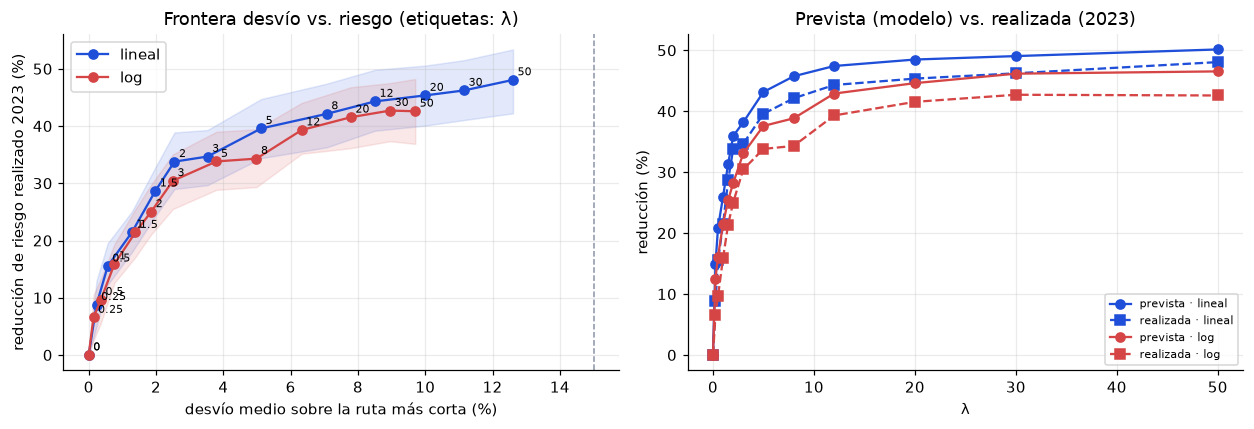

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
for forma, col in (("lineal", AZUL), ("log", ROJO)):
    b = bar[bar.forma == forma]
    ax[0].plot(b.desvio_medio * 100, b.red_realizada * 100, "o-", color=col, label=forma)
    ax[0].fill_between(b.desvio_medio * 100, b.red_real_lo * 100, b.red_real_hi * 100, color=col, alpha=.12)
    for _, x in b.iterrows(): ax[0].annotate(f"{x.lam:g}", (x.desvio_medio * 100, x.red_realizada * 100), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[0].axvline(TOPE_MEDIO * 100, color=GRIS, ls="--", lw=1); ax[0].set(xlabel="desvío medio sobre la ruta más corta (%)", ylabel="reducción de riesgo realizado 2023 (%)", title="Frontera desvío vs. riesgo (etiquetas: λ)"); ax[0].legend()
for forma, col in (("lineal", AZUL), ("log", ROJO)):
    b = bar[bar.forma == forma]; ax[1].plot(b.lam, b.red_prevista * 100, "o-", color=col, label=f"prevista · {forma}"); ax[1].plot(b.lam, b.red_realizada * 100, "s--", color=col, label=f"realizada · {forma}")
ax[1].set(xlabel="λ", ylabel="reducción (%)", title="Prevista (modelo) vs. realizada (2023)"); ax[1].legend(fontsize=7)
plt.tight_layout(); guardar_fig("ruteo_frontera_lambda.png")

## 4. Elección de λ y comprobaciones — ¿qué vamos a hacer?

**Regla de decisión (explícita y editable):** entre las combinaciones forma × λ con **desvío medio ≤ 15 %** y **desvío p90 ≤ 30 %**, buscar la **mayor reducción de riesgo realizado en 2023** y, entre las que logran al menos el **95 %** de esa reducción máxima, quedarse con la de **menor desvío** (criterio de parsimonia).
Los topes son una decisión de producto (cuánto más aceptan caminar las personas), no un resultado del modelo. Luego se comprueba que:

1. λ = 0 reproduce la ruta más corta (contra `networkx`),
2. el riesgo previsto no sube al aumentar λ, y
3. la variante **nocturna** (riesgo nocturno) también reduce lo que ocurrió de noche.

In [6]:
ok = bar[(bar.desvio_medio <= TOPE_MEDIO) & (bar.desvio_p90 <= TOPE_P90)]
mejor = ok.red_realizada.max()
cand = ok[ok.red_realizada >= 0.95 * mejor]                      # parsimonia: no exigir más λ del necesario para casi la mejor reducción
elegido = cand.sort_values(["desvio_medio", "lam"]).iloc[0]
print(f"Mejor reducción realizada dentro de los topes: {mejor:.1%} · candidatas con >= 95 % de eso: {len(cand)}")
print("Candidatas dentro de los topes:"); print(ok[["forma", "lam", "desvio_medio", "desvio_p90", "red_prevista", "red_realizada"]].to_string(index=False))
print(f"\n>>> λ elegido: forma={elegido.forma}, λ={elegido.lam:g} · desvío medio {elegido.desvio_medio:.1%}, p90 {elegido.desvio_p90:.1%} · reducción realizada {elegido.red_realizada:.1%} (IC95 {elegido.red_real_lo:.1%} a {elegido.red_real_hi:.1%})")
# 1) λ=0 == ruta más corta según networkx
import networkx as nx
Gx = nx.Graph(); fa, fb = A0.nonzero(); Gx.add_weighted_edges_from(zip(fa.tolist(), fb.tolist(), np.asarray(A0[fa, fb]).ravel().tolist()))
chk = pares.sample(40, random_state=SEED)
dif = [abs(nx.shortest_path_length(Gx, int(o), int(d), weight="weight") - base["total"].query("orig==@o and dest==@d").largo.iloc[0]) for o, d in zip(chk.orig, chk.dest)]
print(f"1) λ=0 vs networkx: diferencia máxima {max(dif):.2e} m en {len(dif)} pares")
# 2) monotonía
for forma in ("lineal", "log"):
    r = bar[bar.forma == forma].red_prevista.values; print(f"2) {forma}: reducción prevista no decreciente con λ: {bool(np.all(np.diff(r) > -1e-3))}")
# 3) variante nocturna con el mismo λ
rn = correr(elegido.forma, elegido.lam, "noche"); mn = rn.merge(base["noche"], on=["orig", "dest"], suffixes=("", "_0"))
print(f"3) noche (riesgo nocturno): desvío medio {(mn.largo/mn.largo_0-1).mean():.1%} · reducción prevista {1-mn.pred_km.mean()/mn.pred_km_0.mean():.1%} · reducción realizada de noche {1-mn.real_km.mean()/mn.real_km_0.mean():.1%}")
# por tipo de punto de acceso
dd = detalle[(elegido.forma, elegido.lam)].merge(base["total"], on=["orig", "dest"], suffixes=("", "_0")).merge(pares[["orig", "dest", "tipo"]], on=["orig", "dest"])
print("\nPor tipo de acceso:"); print(dd.groupby("tipo").apply(lambda g: pd.Series({"pares": len(g), "desvío_medio": (g.largo / g.largo_0 - 1).mean(), "reducción_realizada": 1 - g.real_km.mean() / g.real_km_0.mean()})).round(3).to_string())
json.dump({"forma": elegido.forma, "lambda": float(elegido.lam), "tope_desvio_medio": TOPE_MEDIO, "tope_desvio_p90": TOPE_P90,
           "desvio_medio": float(elegido.desvio_medio), "reduccion_realizada_valid2023": float(elegido.red_realizada)}, open(OUTD / "lambda_elegido.json", "w"), indent=2)

Mejor reducción realizada dentro de los topes: 46.2% · candidatas con >= 95 % de eso: 3
Candidatas dentro de los topes:
 forma    lam  desvio_medio  desvio_p90  red_prevista  red_realizada
lineal  0.000         0.000       0.000         0.000          0.000
lineal  0.250         0.002       0.007         0.150          0.088
lineal  0.500         0.006       0.019         0.209          0.155
lineal  1.000         0.013       0.041         0.260          0.214
lineal  1.500         0.020       0.056         0.313          0.286
lineal  2.000         0.025       0.072         0.359          0.338
lineal  3.000         0.035       0.102         0.382          0.347
lineal  5.000         0.051       0.143         0.432          0.396
lineal  8.000         0.071       0.195         0.457          0.421
lineal 12.000         0.085       0.236         0.474          0.443
lineal 20.000         0.100       0.272         0.485          0.454
lineal 30.000         0.112       0.295         0.49

1) λ=0 vs networkx: diferencia máxima 1.14e-13 m en 40 pares
2) lineal: reducción prevista no decreciente con λ: True
2) log: reducción prevista no decreciente con λ: True


3) noche (riesgo nocturno): desvío medio 9.3% · reducción prevista 50.0% · reducción realizada de noche 48.3%

Por tipo de acceso:
              pares  desvío_medio  reducción_realizada
tipo                                                  
alimentador 444.000         0.061                0.531
corredor    462.000         0.094                0.433
metro_l1    156.000         0.104                0.443
troncal     258.000         0.098                0.423


### Qué encontramos (elección de λ)

- **λ elegido: forma lineal, λ = 12** → desvío medio **8,5 %** (p90 23,6 %), reducción de riesgo realizado en 2023 de **44,3 %** (IC 95 % 39,2–49,8 %). Cumple los topes (≤ 15 % medio, ≤ 30 % p90). La mejor reducción dentro de los topes es 46,2 % (λ = 30); tres combinaciones logran al menos el 95 % de ella y λ = 12 es la de menor desvío.
- **Comprobaciones:** λ = 0 coincide con el camino más corto de `networkx` (diferencia máxima 1,1e-13 m en 40 pares); la reducción prevista no baja al subir λ en ninguna de las dos formas; en la **variante nocturna** (riesgo nocturno) el desvío es 9,3 % y la reducción de lo ocurrido de noche es **48,3 %**.
- **Por tipo de punto de acceso (validación):**

| Tipo | Pares | Desvío medio | Reducción realizada |
|---|---:|---:|---:|
| Alimentador | 444 | 6,1 % | 53,1 % |
| Corredor | 462 | 9,4 % | 43,3 % |
| Metro L1 | 156 | 10,4 % | 44,3 % |
| Troncal | 258 | 9,8 % | 42,3 % |

**Limitaciones de esta medición:**
- "Riesgo realizado" son **denuncias registradas**, no delito: una ruta que evita calles con más denuncias también evita calles donde más se denuncia.
- Los topes de desvío (15 % y 30 %) son una decisión de producto, editable arriba.
- Los conteos por tipo pueden repetirse cuando dos accesos de distinto tipo comparten nodo de la red.

**Decisión:** λ = 12 con costo lineal como valor inicial del backend, configurable, y la opción de ruta más corta siempre visible.

## 5. Confirmación en el test (enero–agosto de 2024) — ¿qué vamos a hacer?

λ y la forma del costo ya están elegidos con 2023. Aquí se **mide una sola vez** qué pasa con ellos en el test: el riesgo se calcula con modelos entrenados hasta 2023 y se compara con lo que realmente ocurrió en enero–agosto de 2024.
No se vuelve a elegir nada con estos resultados. Se usan los **mismos pares** origen-destino.

In [7]:
bT = {c: correr("lineal", 0, c, T) for c in ("total", "noche")}
rT = correr(elegido.forma, elegido.lam, "total", T); mT = rT.merge(bT["total"], on=["orig", "dest"], suffixes=("", "_0"))
desvT = mT.largo / mT.largo_0 - 1; red_pT = 1 - mT.pred_km.mean() / mT.pred_km_0.mean(); red_rT = 1 - mT.real_km.mean() / mT.real_km_0.mean()
bsT = []
for _ in range(500):
    mm = mT[mT.orig.isin(rng.choice(mT.orig.unique(), mT.orig.nunique()))]; bsT.append(1 - mm.real_km.mean() / mm.real_km_0.mean())
print(f"TEST 2024 (forma={elegido.forma}, λ={elegido.lam:g}): desvío medio {desvT.mean():.1%} · p90 {desvT.quantile(.9):.1%} · reducción prevista {red_pT:.1%} · reducción REALIZADA {red_rT:.1%} (IC95 {np.percentile(bsT, 2.5):.1%} a {np.percentile(bsT, 97.5):.1%})")
print(f"Validación 2023 (para comparar):           desvío medio {elegido.desvio_medio:.1%} · p90 {elegido.desvio_p90:.1%} · reducción prevista {elegido.red_prevista:.1%} · reducción realizada {elegido.red_realizada:.1%}")
rnT = correr(elegido.forma, elegido.lam, "noche", T); mnT = rnT.merge(bT["noche"], on=["orig", "dest"], suffixes=("", "_0"))
print(f"Noche en test: desvío medio {(mnT.largo/mnT.largo_0-1).mean():.1%} · reducción realizada de noche {1-mnT.real_km.mean()/mnT.real_km_0.mean():.1%}")
ddT = mT.merge(pares[["orig", "dest", "tipo"]], on=["orig", "dest"])
print("\nPor tipo de acceso (test):"); print(ddT.groupby("tipo").apply(lambda g: pd.Series({"pares": len(g), "desvío_medio": (g.largo / g.largo_0 - 1).mean(), "reducción_realizada": 1 - g.real_km.mean() / g.real_km_0.mean()})).round(3).to_string())
json.dump({"test_2024": {"forma": elegido.forma, "lambda": float(elegido.lam), "desvio_medio": float(desvT.mean()), "desvio_p90": float(desvT.quantile(.9)), "reduccion_prevista": float(red_pT),
           "reduccion_realizada": float(red_rT), "ic95": [float(np.percentile(bsT, 2.5)), float(np.percentile(bsT, 97.5))]}}, open(OUTD / "lambda_confirmacion_test.json", "w"), indent=2)

TEST 2024 (forma=lineal, λ=12): desvío medio 8.7% · p90 22.6% · reducción prevista 45.7% · reducción REALIZADA 43.8% (IC95 38.6% a 50.2%)
Validación 2023 (para comparar):           desvío medio 8.5% · p90 23.6% · reducción prevista 47.4% · reducción realizada 44.3%


Noche en test: desvío medio 10.4% · reducción realizada de noche 50.6%

Por tipo de acceso (test):
              pares  desvío_medio  reducción_realizada
tipo                                                  
alimentador 444.000         0.067                0.703
corredor    462.000         0.089                0.451
metro_l1    156.000         0.104                0.276
troncal     258.000         0.107                0.472


### Qué encontramos (confirmación en test, enero–agosto de 2024)

Con λ = 12 y costo lineal, riesgo previsto por modelos entrenados hasta 2023 y eventos reales de enero–agosto de 2024:

| | Desvío medio | Desvío p90 | Reducción prevista | Reducción realizada |
|---|---:|---:|---:|---:|
| Validación 2023 | 8,5 % | 23,6 % | 47,4 % | 44,3 % |
| **Test 2024** | **8,7 %** | **22,6 %** | **45,7 %** | **43,8 % (IC 95 % 38,6–50,2)** |

- La ganancia **se mantiene en el test**: 43,8 % menos riesgo realizado con 8,7 % de desvío medio.
- **De noche** (riesgo nocturno): desvío medio 10,4 % y 50,6 % menos de lo ocurrido de noche.
- Por tipo de acceso en el test: alimentador 70,3 % (desvío 6,7 %), corredor 45,1 % (8,9 %), troncal 47,2 % (10,7 %) y **Metro 27,6 %** (10,4 %); en Metro la muestra es de solo 156 pares.

**Decisión:** no se vuelve a elegir nada con estos números; λ = 12 queda como valor inicial.

## 6. Exportar el grafo para el backend — ¿qué vamos a hacer?

El backend no usa `osmnx` ni reentrena: carga un archivo compacto con el grafo y el riesgo 0–1 (producción: modelo con eventos hasta agosto de 2024) y aplica
`largo × (1 + λ·riesgo)` con el λ elegido. Se guarda `export/grafo_ruteo.parquet`.

In [8]:
rp = pd.read_parquet(OUTD / "riesgo_segmentos.parquet").set_index("seg_id").reindex(segz.seg_id)
g = pd.DataFrame({"seg_id": segz.seg_id.values, "u": segz.u.values, "v": segz.v.values, "largo_m": L.round(1), "via": segz.via.values,
                  "riesgo_total": rp.riesgo01_total.values.round(4), "riesgo_noche": rp.riesgo01_noche.values.round(4), "riesgo_dia": rp.riesgo01_dia.values.round(4)})
g.to_parquet(EXP / "grafo_ruteo.parquet", index=False)
print(f"Exportado: {len(g):,} segmentos · {(EXP / 'grafo_ruteo.parquet').stat().st_size/1e6:.1f} MB · riesgo_total media {g.riesgo_total.mean():.3f}")

Exportado: 146,607 segmentos · 4.0 MB · riesgo_total media 0.265


### Conclusiones

1. El riesgo del modelo se usa como peso de un grafo y **Dijkstra encuentra rutas casi igual de cortas y mucho menos expuestas**: con λ = 12 (lineal), 8,5 % más largas y 44,3 % menos riesgo realizado en 2023 (validación) y 43,8 % en el test de enero–agosto de 2024.
2. λ **no se fijó a ojo**: se partió de lo que usan otros proyectos (λ 0–3 y 1,5), se amplió la grilla hasta que la ganancia se aplanó (λ ≈ 12–30) y se eligió con una regla explícita (tope de desvío + parsimonia).
3. La forma lineal rinde un poco más que la logarítmica con el mismo desvío.
4. Funciona también de noche con el riesgo nocturno (48–51 % de reducción).
5. Es evidencia **sobre denuncias registradas**; el efecto es menor en Metro (28 % en el test) que en alimentadores, corredores y troncales.
6. El archivo `export/grafo_ruteo.parquet` (146 607 segmentos, 4 MB) tiene lo que necesita el backend, que no requiere `osmnx`.